# Machine Learning: Exercise session 04

In this exercise session we will focus on Ridge and Lasso regression. You will learn how to fit, predict, and cross-validate these models.

In the first problem, we will continue using the housing dataset where we added two additional variables `X1` and `X2`.
You can download the data from Moodle in this week's section.

In the second problem we will derive the closed-form solution for the Ridge regression (notice that Lasso regression has no closed-form solution).

## Problem 1

### 1. Load data and create a test set

In [76]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Import the clean housing dataset (with `X1`, `X2`) using `pd.read_csv` and take a quick look at it, to verify that it is in the desired shape (display the dataframe, check its "infos").

In [77]:
df = pd.read_csv("housing_clean_with_X1X2.csv")
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20417 entries, 0 to 20416
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   median_house_value    20417 non-null  int64  
 1   ocean_proximity_enc   20417 non-null  int64  
 2   longitude             20417 non-null  float64
 3   latitude              20417 non-null  float64
 4   housing_median_age    20417 non-null  int64  
 5   median_income         20417 non-null  float64
 6   rooms_per_bedroom     20417 non-null  float64
 7   rooms_per_household   20417 non-null  float64
 8   people_per_household  20417 non-null  float64
 9   X1                    20417 non-null  float64
 10  X2                    20417 non-null  float64
dtypes: float64(8), int64(3)
memory usage: 1.7 MB


Separate the dataframe into the features `X` and the target variable `y`: (remember, we want to predict the median house value, given the other variables)

In [78]:
X = df.drop(columns="median_house_value")
y = df["median_house_value"]   # single brackets, so y is 1-D

Using the function `train_test_split`, split the dataset into training and test set. Set `test_size = 0.95` and `random_state = 12`. 

*Notice that we choose a very large fraction of test data because we want to see whether the Ridge and Lasso regression can handle the high-dimensional setting.*

In [79]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.95, random_state=12)

### 2. Define models

Since ridge regression and lasso penalize the value of the coefficients $\beta_i$, it is important that all features are on a similar scale.
Is this the case here?

*Hint:* The output of `housing.describe()` gives a good overview over the mean, standard deviation, and relevant quantiles of each (numerical) feature.

In [80]:
df.describe()
#yeah we have to standardize the features before applying the ridge regression

,median_house_value,ocean_proximity_enc,longitude,latitude,housing_median_age,median_income,rooms_per_bedroom,rooms_per_household,people_per_household,X1,X2
count,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000
mean,206867.965568,1.166136,-119.570543,35.631614,28.634912,3.870970,4.984592,5.400583,2.937114,4.980824,5.032444
std,115431.096022,1.420546,2.003755,2.135635,12.591100,1.899041,1.171702,1.885913,0.944461,2.311603,4.010634
min,14999.000000,0.000000,-124.350000,32.540000,1.000000,0.499900,1.000000,0.846154,0.692308,-3.409768,-11.182254
25%,119500.000000,0.000000,-121.800000,33.930000,18.000000,2.563700,4.169683,4.441038,2.429238,3.406365,2.320378
50%,179800.000000,1.000000,-118.490000,34.260000,29.000000,3.536300,4.921739,5.230380,2.817610,4.969657,5.050139
75%,264700.000000,1.000000,-118.010000,37.710000,37.000000,4.743700,5.700364,6.051613,3.281481,6.558337,7.733056
max,500001.000000,4.000000,-114.310000,41.950000,52.000000,15.000100,10.000000,47.515152,41.214286,13.331572,20.305780


Using the class `Ridge` from `sklearn.linear_model`, instantiate a ridge regression estimator with penalty parameter `alpha` set to `0.1` and `fit_intercept=True`.


In [81]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=0.1, fit_intercept=True)

Since the features are on very different scales, it is important that we scale them before performing further analysis.

To this end, create a `Pipeline` consisting of a `StandardScaler` instance and the `Ridge` instance from above.

In [82]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ridge_reg_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge_reg', ridge)
])

Using the class `Lasso` from `sklearn.linear_model`, instantiate a lasso regression object with penalty parameter `alpha` equal to `0.1` and `fit_intercept=True`.

Again, create a `Pipeline` from this object and a `StandardScaler` instance.

In [83]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

lasso = Lasso(alpha=0.1, fit_intercept=True)

lasso_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', lasso)
])


What is the role of the option `fit_intercept`?

insures the model has a $\beta_0$ so an intercept, if you don't have it you model is just a linear combination of your inputs and thier coeficients and that option just adds an intercept.

### 3. Fit Ridge regression

Fit the ridge regression (pipeline) on the training data previously created.

In [84]:
ridge_reg_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge_reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['ocean_proximity_enc','longitude','latitude',...,'people_per_household', 'X1','X2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Compute the root mean square error of the fitted model on both the training and test set. What do you observe?

In [85]:
from sklearn.metrics import mean_squared_error
mse_ridge = mean_squared_error(y_test, ridge_reg_pipe.predict(X_test))
print('mse ridge:', mse_ridge)

mse ridge: 4850001610.109776


### 4. Plot Ridge regression coefficients

We now want to plot the coefficients of the ridge regression for different values of the penalty parameter.

Create a (geometrically spaced) grid, named `ridge_reg_grid`, of penalty values ranging from `1e-2` to `1e6`.

In [86]:
ridge_reg_grid = np.geomspace(1e-2, 1e6, num=100)

Fill in the `??` below to create a list of the parameters found by the ridge regression pipeline for each `alpha` in `ridge_reg_grid`

In [87]:
coefs = []
for alpha in ridge_reg_grid:
    ridge_reg_pipe.set_params(ridge_reg__alpha=alpha)
    ridge_reg_pipe.fit(X_train, y_train)
    coefs.append(ridge_reg_pipe.named_steps['ridge_reg'].coef_)

Plot the coefficients computed above.

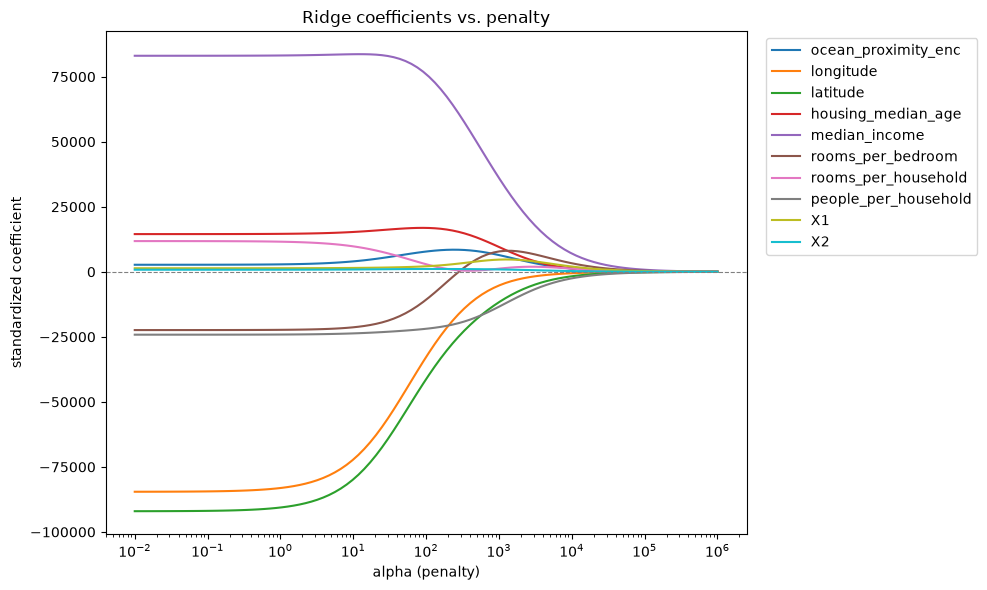

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge_reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['ocean_proximity_enc','longitude','latitude',...,'people_per_household', 'X1','X2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [88]:
coefs = np.array(coefs)   # (100, 10)

plt.figure(figsize=(10, 6))
plt.plot(ridge_reg_grid, coefs)
plt.xscale('log')
plt.axhline(0, color='grey', lw=0.8, ls='--')
plt.xlabel('alpha (penalty)')
plt.ylabel('standardized coefficient')
plt.title('Ridge coefficients vs. penalty')
plt.legend(X_train.columns, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

ridge_reg_pipe.set_params(ridge_reg__alpha=0.1)  # reset for later steps

### 5. Fit Lasso regression

Fit the lasso regression (pipeline) on the training data previously created.

In [89]:
lasso_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['ocean_proximity_enc','longitude','latitude',...,'people_per_household', 'X1','X2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Compute the root mean square error of the fitted model on both the training and test set. What do you observe?

In [90]:
mse_lasso = mean_squared_error(y_test, lasso_pipe.predict(X_test))
print('mse lasso:', mse_lasso)

mse lasso: 4850016320.109542


### 6. Plot Lasso coefficients

As above, we want to plot the coefficients of the lasso regression for different values of the penalty parameter.

Create a (geometrically spaced) grid, named `lasso_grid`, of penalty values ranging from `1` to `1e6`.

In [ ]:
lasso_grid = np.geomspace(1, 1e6, num=100)

* Fill in the `??` below.

In [ ]:
coefs = []
for alpha in lasso_grid:
    lasso_pipe.set_params(lasso__alpha=alpha)
    lasso_pipe.fit(X_train, y_train)
    coefs.append(lasso_pipe.named_steps['lasso'].coef_)

Plot the coefficients computed above.

In [ ]:
coefs = np.array(coefs)   # (100, 10)
plt.figure(figsize=(10, 6))
plt.plot(lasso_grid, coefs)
plt.xscale('log')
plt.axhline(0, color='grey', lw=0.8, ls='--')
plt.xlabel('Lasso Regularization (alpha)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Coefficient Path')
plt.legend(X_train.columns, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 7. Prepare Cross Validation

At this point, we want to find the optimal penalty parameter for our models.
We will use 10-fold cross-validation.

Using the `KFold` class from `sklearn.model_selection` instatiate an object named `folds`.
Set the number of splits equal to 10, the random seed equal to 42, and make sure to shuffle the rows.

In [94]:
from sklearn.model_selection import KFold

folds = KFold(n_splits=10, shuffle=True, random_state=42)

### 8. CV for Ridge

Create a dictionary with the key-value pair `"ridge_reg__alpha"`, `ridge_reg_grid`. What is the use of this object?

In [95]:
ridge_param_grid = {"ridge_reg__alpha": ridge_reg_grid}

Import the class `GridSearchCV` from `sklearn.model_selection` and use it to instantiate a **cross-validation object** for the ridge regression. Make sure to include the following parameters: `estimator`, `param_grid`, `scoring`, `cv`.

In [96]:
from sklearn.model_selection import GridSearchCV

ridge_cv = GridSearchCV(
    estimator=ridge_reg_pipe,
    param_grid=ridge_param_grid,
    scoring="neg_mean_squared_error",
    cv=folds,
)

Run the cross-validation by calling the `fit` method of the **cross-validation object** that you created at the point before.

In [97]:
ridge_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(alpha=0.1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge_reg__alpha': array([1.0000...00000000e+06])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

We want to plot the cross-validation error against different values of the penalty parameter. Fill in the `??`.

In [ ]:
# Choose best model that minimizes cv_err
mean_scores = -ridge_cv.cv_results_["mean_test_score"]
se_scores = ridge_cv.cv_results_["std_test_score"] / np.sqrt(folds.n_splits)
alphas = ridge_cv.cv_results_["param_ridge_reg__alpha"].data.astype(float)

best_index = np.argmin(mean_scores)
min_alpha_ridge = alphas[best_index]
threshold_ridge = mean_scores[best_index] + se_scores[best_index]
one_se_rule_alpha_ridge = alphas[mean_scores <= threshold_ridge].max()

print("Minimum alpha:", min_alpha_ridge)
print("1-SD alpha:", one_se_rule_alpha_ridge)
print("Best score for ridge:", np.sqrt(np.min(mean_scores)))

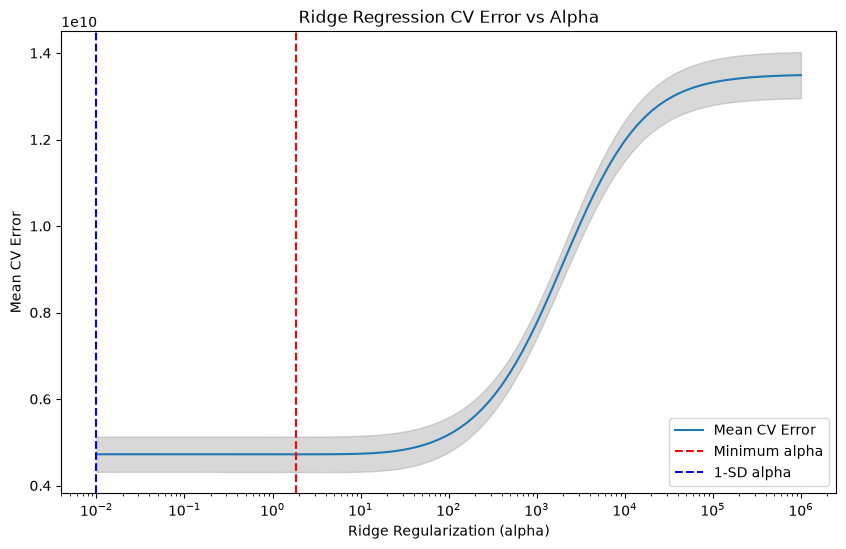

In [99]:
plt.figure(figsize=(10, 6))
plt.plot(alphas, mean_scores, label="Mean CV Error")
plt.fill_between(alphas, mean_scores - se_scores, mean_scores + se_scores, color="gray", alpha=0.3)
plt.axvline(min_alpha_ridge, color="red", linestyle="--", label="Minimum alpha")
plt.axvline(one_se_rule_alpha_ridge, color="blue", linestyle="--", label="1-SD alpha")
plt.xscale("log")
plt.xlabel("Ridge Regularization (alpha)")
plt.ylabel("Mean CV Error")
plt.title("Ridge Regression CV Error vs Alpha")
plt.legend()
plt.show()

### 9. CV for Lasso

Create a dictionary with the key-value pair `"lasso__alpha"`, `lasso_grid`. What is the use of this object?

In [ ]:
lasso_param_grid = {"lasso__alpha": lasso_grid}

Create a cross-validation object for the lasso regression. Make sure to specify the following parameters: `estimator`, `param_grid`, `scoring`, `cv`.

In [104]:
lasso_cv = GridSearchCV(
    estimator=lasso_pipe,
    param_grid=lasso_param_grid,
    scoring="neg_mean_squared_error",
    cv=folds,
)

Run the cross-validation by calling the `fit` method of the **cross-validation object** that you created at the point before.

In [ ]:
lasso_cv.fit(X_train, y_train)

We want to plot the cross-validation error against different values of the penalty parameter. Fill in the `??`.

In [ ]:
# Choose best model that minimizes the cv_err
mean_scores = -lasso_cv.cv_results_["mean_test_score"]
se_scores = lasso_cv.cv_results_["std_test_score"] / np.sqrt(folds.n_splits)
alphas = lasso_cv.cv_results_["param_lasso__alpha"].data.astype(float)

best_index = np.argmin(mean_scores)
min_alpha_lasso = alphas[best_index]
threshold_lasso = mean_scores[best_index] + se_scores[best_index]
one_se_rule_alpha_lasso = alphas[mean_scores <= threshold_lasso].max()

print("Minimum alpha:", min_alpha_lasso)
print("1-SD alpha:", one_se_rule_alpha_lasso)
print("Best score for lasso:", np.sqrt(np.min(mean_scores)))

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(alphas, mean_scores, label="Mean CV Error")
plt.fill_between(alphas, mean_scores - se_scores, mean_scores + se_scores, color="gray", alpha=0.3)
plt.axvline(min_alpha_lasso, color="red", linestyle="--", label="Minimum alpha")
plt.axvline(one_se_rule_alpha_lasso, color="blue", linestyle="--", label="1-SD alpha")
plt.xscale("log")
plt.xlabel("Lasso Regularization (alpha)")
plt.ylabel("Mean CV Error")
plt.title("Lasso Regression CV Error vs Alpha")
plt.legend()
plt.show()

### 10. Compute performance of the two best models

Given the optimal tuning parameter of the ridge and lasso regression, refit both models on the entire training data set.
Furthermore, compute their root mean square error on the test set. How do they compare to the errors obtained before performing the cross-validation?


In [ ]:
# Refit best ridge on whole training data and evaluate on test
??

In [ ]:
# Refit best lasso on whole training data and evaluate on test
??

## Problem 2

In this problem, you are asked to derive the closed-form solution for the ridge regression coefficients.

Let $\mathbf{X}\in\mathbb{R}^{n\times p}$ denote the matrix of predictors, and let $\mathbf{y}\in\mathbb{R}^n$ denote the target vector.

The optimal ridge regression coefficient vector $\beta^*$, with parameter $\lambda > 0$, is defined as

$$\beta^* := \arg\min_{\beta\in\mathbb{R}^p} \ (\mathbf{y} - \mathbf{X}\beta)^T(\mathbf{y} - \mathbf{X}\beta) + \lambda \beta ^T\beta.$$

Show that 


$$\beta^*  = (\mathbf{X}^T\mathbf{X} + \lambda \mathbf{I}_p)^{-1} \mathbf{X}^T \mathbf{y},$$

where $\mathbf{I}_p$ denote the identity matrix of size $p\times p$.